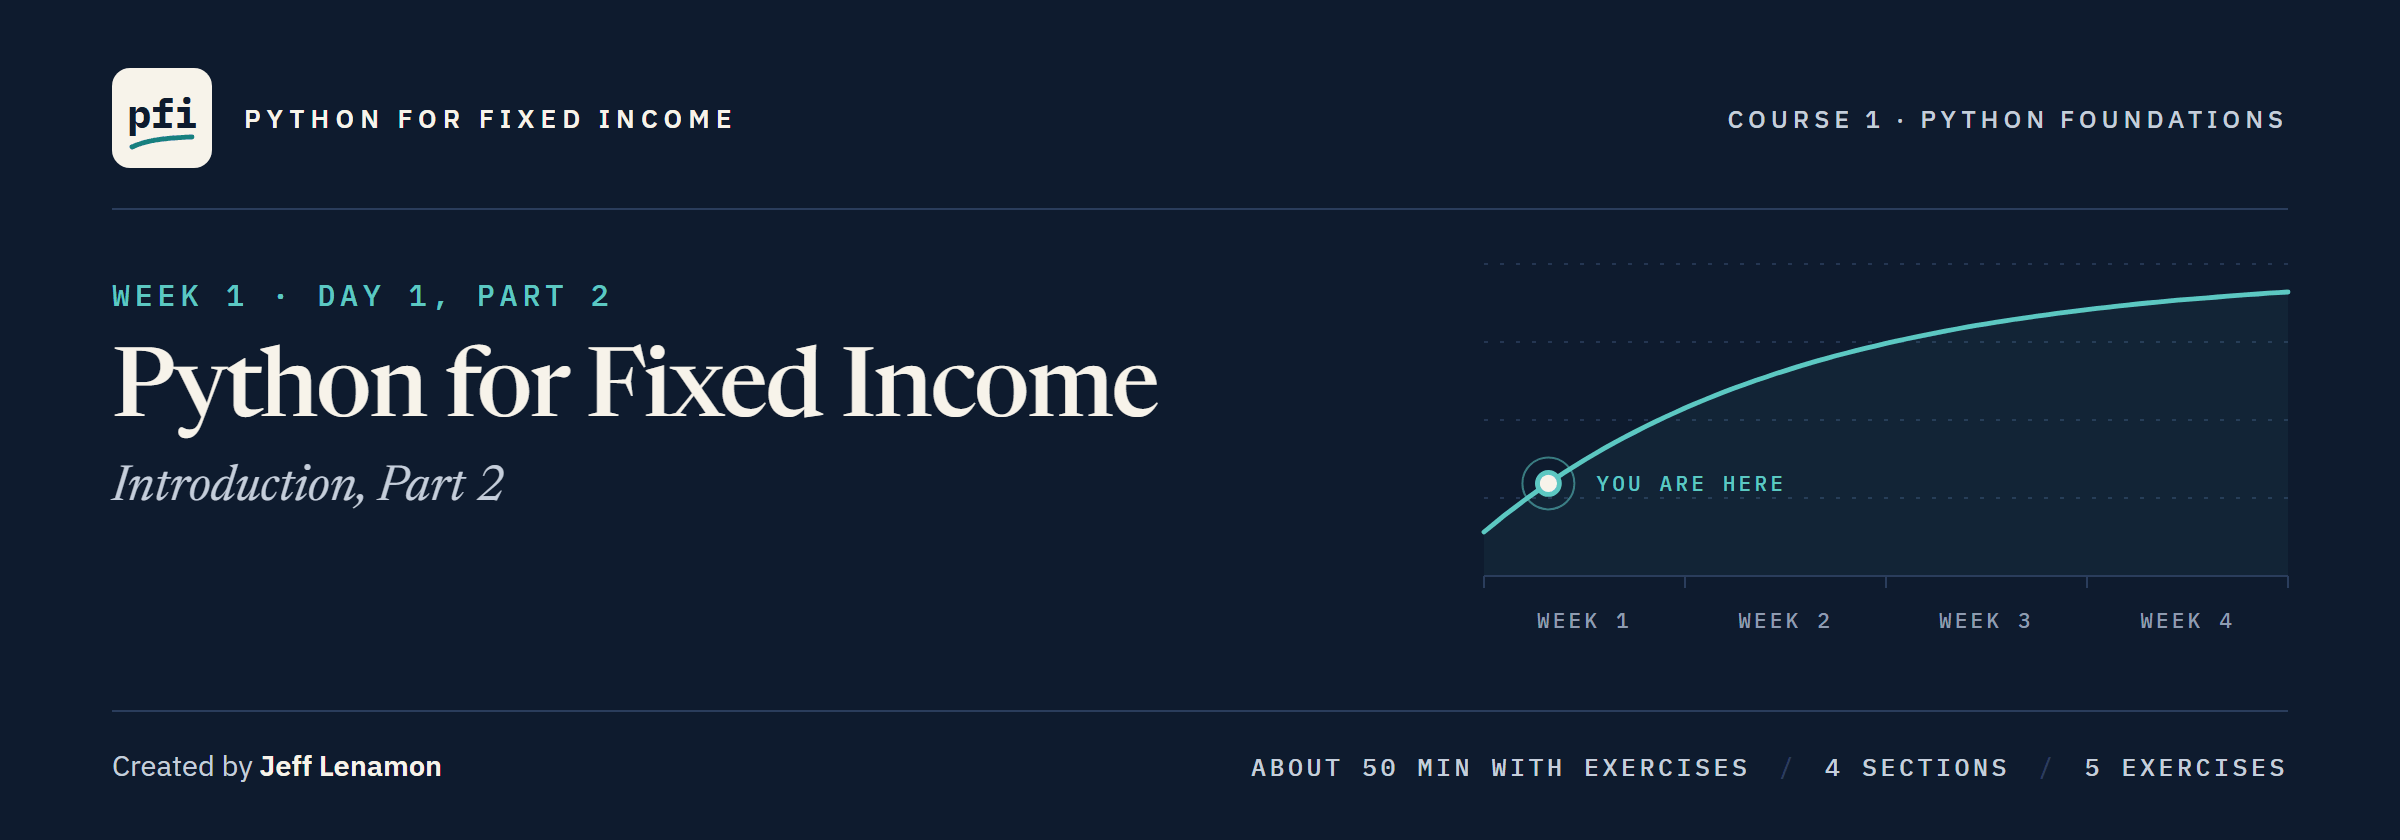

# Python for Fixed Income: Introduction, Part 2

Week 1, Day 1, Part 2. Decisions, loops, and functions, on the same desk of four bonds.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course01_python_foundations/week1/day1_part2/01_part2_python_for_fixed_income_intro.ipynb)

## The Desk Lead's Third Note

Part 1's note is answered, and a third one is waiting:

> The book is in Python. Now make it work: tell me which of our four bonds are investment grade, cost every position in one go, and turn the coupon sum into something I can reuse.

<table align="left">
<tr><th align="left">Ticker</th><th align="left">Issuer</th><th align="left">Coupon (%)</th><th align="left">Maturity</th><th align="left">Price</th><th align="left">Rating</th><th align="left">Face held</th></tr>
<tr><td align="left">QVNE</td><td align="left">Quorvane Energy</td><td align="left">5.25</td><td align="left">2033</td><td align="left">98.50</td><td align="left">BBB</td><td align="left">1,500,000</td></tr>
<tr><td align="left">DNMR</td><td align="left">Dunmarrow Rail</td><td align="left">6.125</td><td align="left">2034</td><td align="left">103.25</td><td align="left">BB+</td><td align="left">500,000</td></tr>
<tr><td align="left">PLWK</td><td align="left">Pellwick Paper</td><td align="left">4.75</td><td align="left">2031</td><td align="left">95.00</td><td align="left">A-</td><td align="left">750,000</td></tr>
<tr><td align="left">HLVF</td><td align="left">Halvering Foods</td><td align="left">7.50</td><td align="left">2032</td><td align="left">101.00</td><td align="left">B+</td><td align="left">250,000</td></tr>
</table>
<br clear="left">

The issuers are invented.

### Part 1's Book in One Cell

A new notebook starts with an empty kernel, so the book is stored again.

**Run the next cell: it stores Part 1's book.**

In [1]:
# Part 1's lists, one per column, the bonds in the same order
ticker_list = ['QVNE', 'DNMR', 'PLWK', 'HLVF']
coupon_list = [5.25, 6.125, 4.75, 7.5]
price_list = [98.5, 103.25, 95.0, 101.0]
rating_list = ['BBB', 'BB+', 'A-', 'B+']
face_list = [1500000, 500000, 750000, 250000]

# QVNE as a dictionary, at its latest mark of 99.25
bond = {'Ticker': 'QVNE', 'Coupon': 5.25, 'Maturity': 2033,
        'Price': 99.25, 'Rating': 'BBB', 'Sector': 'Energy'}

# one dictionary per bond
holdings = [
    {'Ticker': 'QVNE', 'Price': 98.5, 'Face': 1500000},
    {'Ticker': 'DNMR', 'Price': 103.25, 'Face': 500000},
    {'Ticker': 'PLWK', 'Price': 95.0, 'Face': 750000},
    {'Ticker': 'HLVF', 'Price': 101.0, 'Face': 250000},
]
print(f'The desk holds {len(ticker_list)} bonds and {sum(face_list):,} face')

The desk holds 4 bonds and 3,000,000 face


## Your Route Through Day 1, Part 2

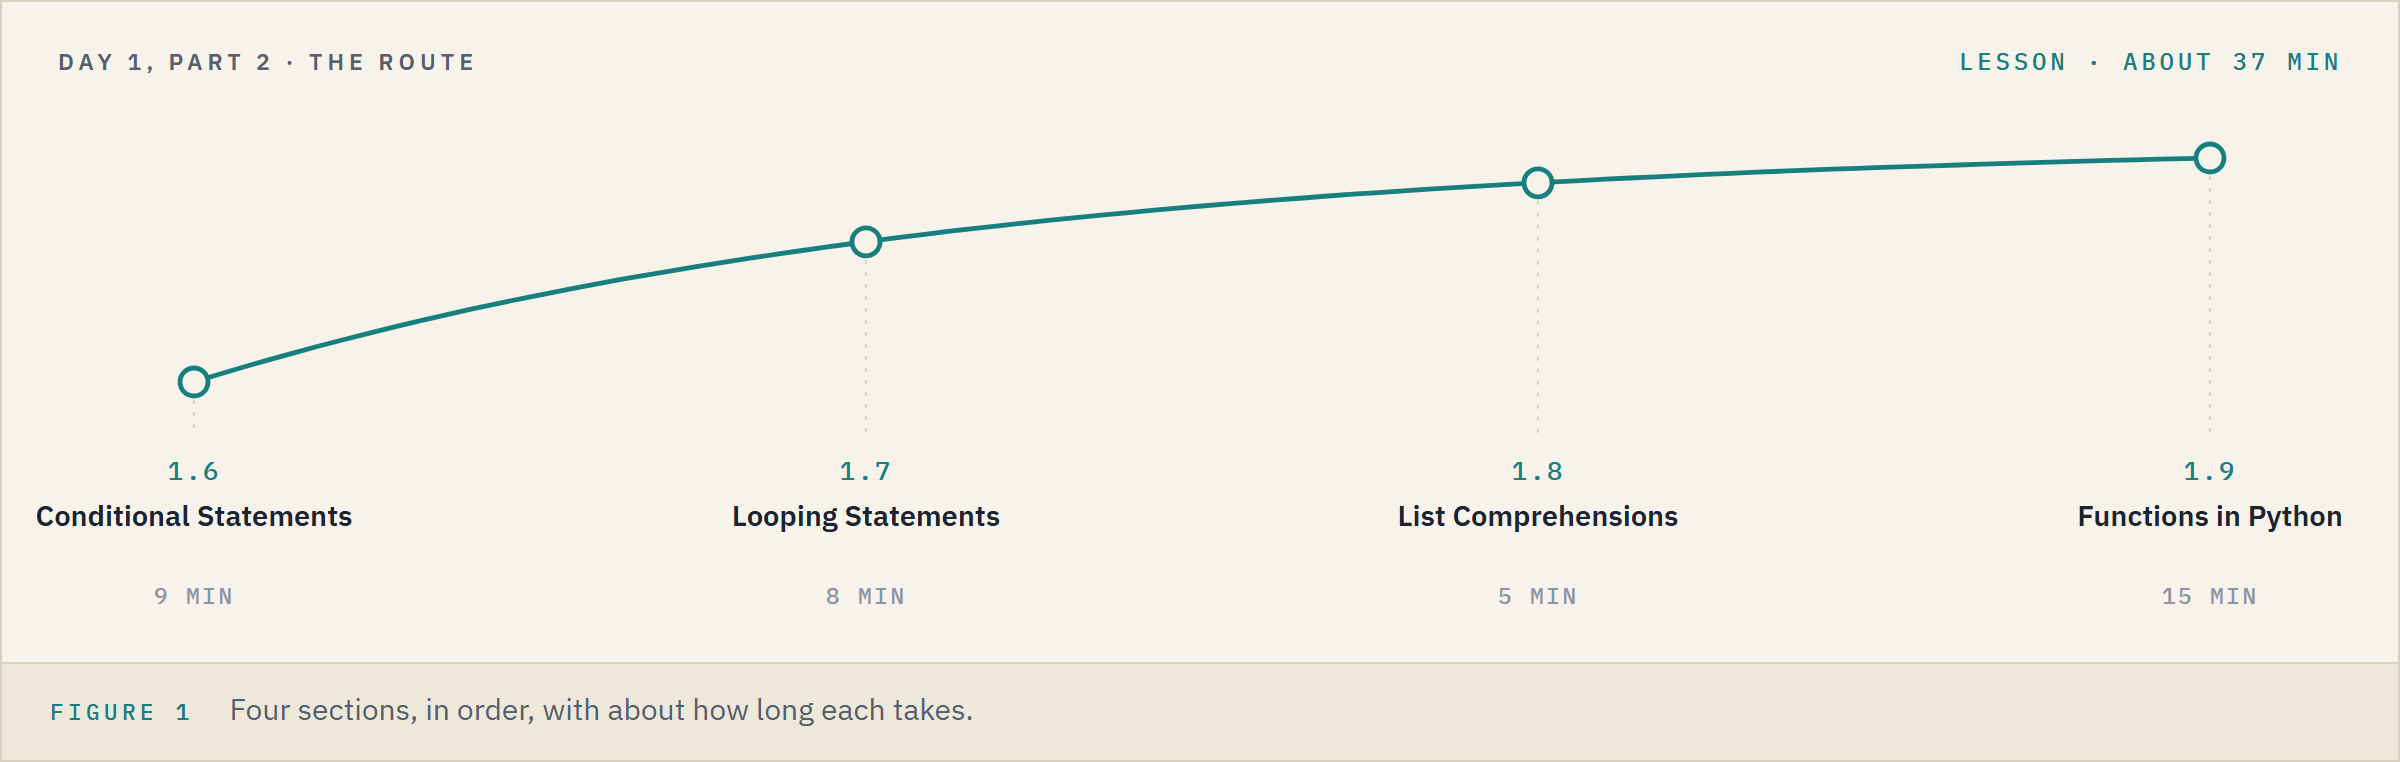

**Time.** About 37 minutes for the lesson, then about 15 for the five exercises.

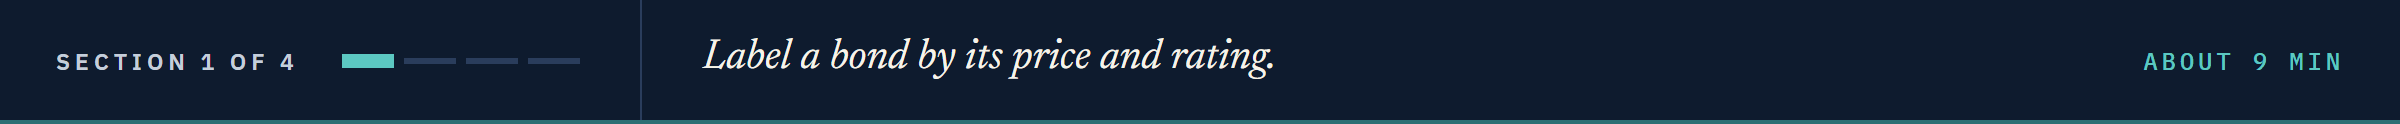

## 1.6 Conditional Statements

### Above, Below, or at Par

Above 100 a bond trades at a **premium**, below 100 at a **discount**.
A **conditional** runs a block of lines only when its test is true:

```
if test:
    lines run when the test is true
else:
    lines run when it is false
```

The colon ends the test, and the indented lines under it are its **block**.
The indent is part of the language: it is how Python knows which lines belong to the `if`.
Press Enter after a colon and the editor indents the next line for you.

Q. Does QVNE, at 98.50, trade at a discount?

In [2]:
# QVNE's price, per 100 face
price = 98.5
# the test, then a colon; the indented line runs only when the test is true
if price < 100:
    print('QVNE trades at a discount')
else:
    print('QVNE does not trade at a discount')

QVNE trades at a discount


98.5 is below 100, so the `if` block ran and the `else` block was skipped.
A price can also sit exactly at par: `elif`, short for else if, adds a test:

```
if test:
    lines
elif another test:
    lines
else:
    lines
```

Q. Does DNMR, at 103.25, trade at a premium, at a discount, or at par?

In [3]:
# DNMR's price, per 100 face
price = 103.25
if price > 100:
    print('DNMR trades at a premium')
elif price < 100:
    print('DNMR trades at a discount')
else:
    print('DNMR trades at par')

DNMR trades at a premium


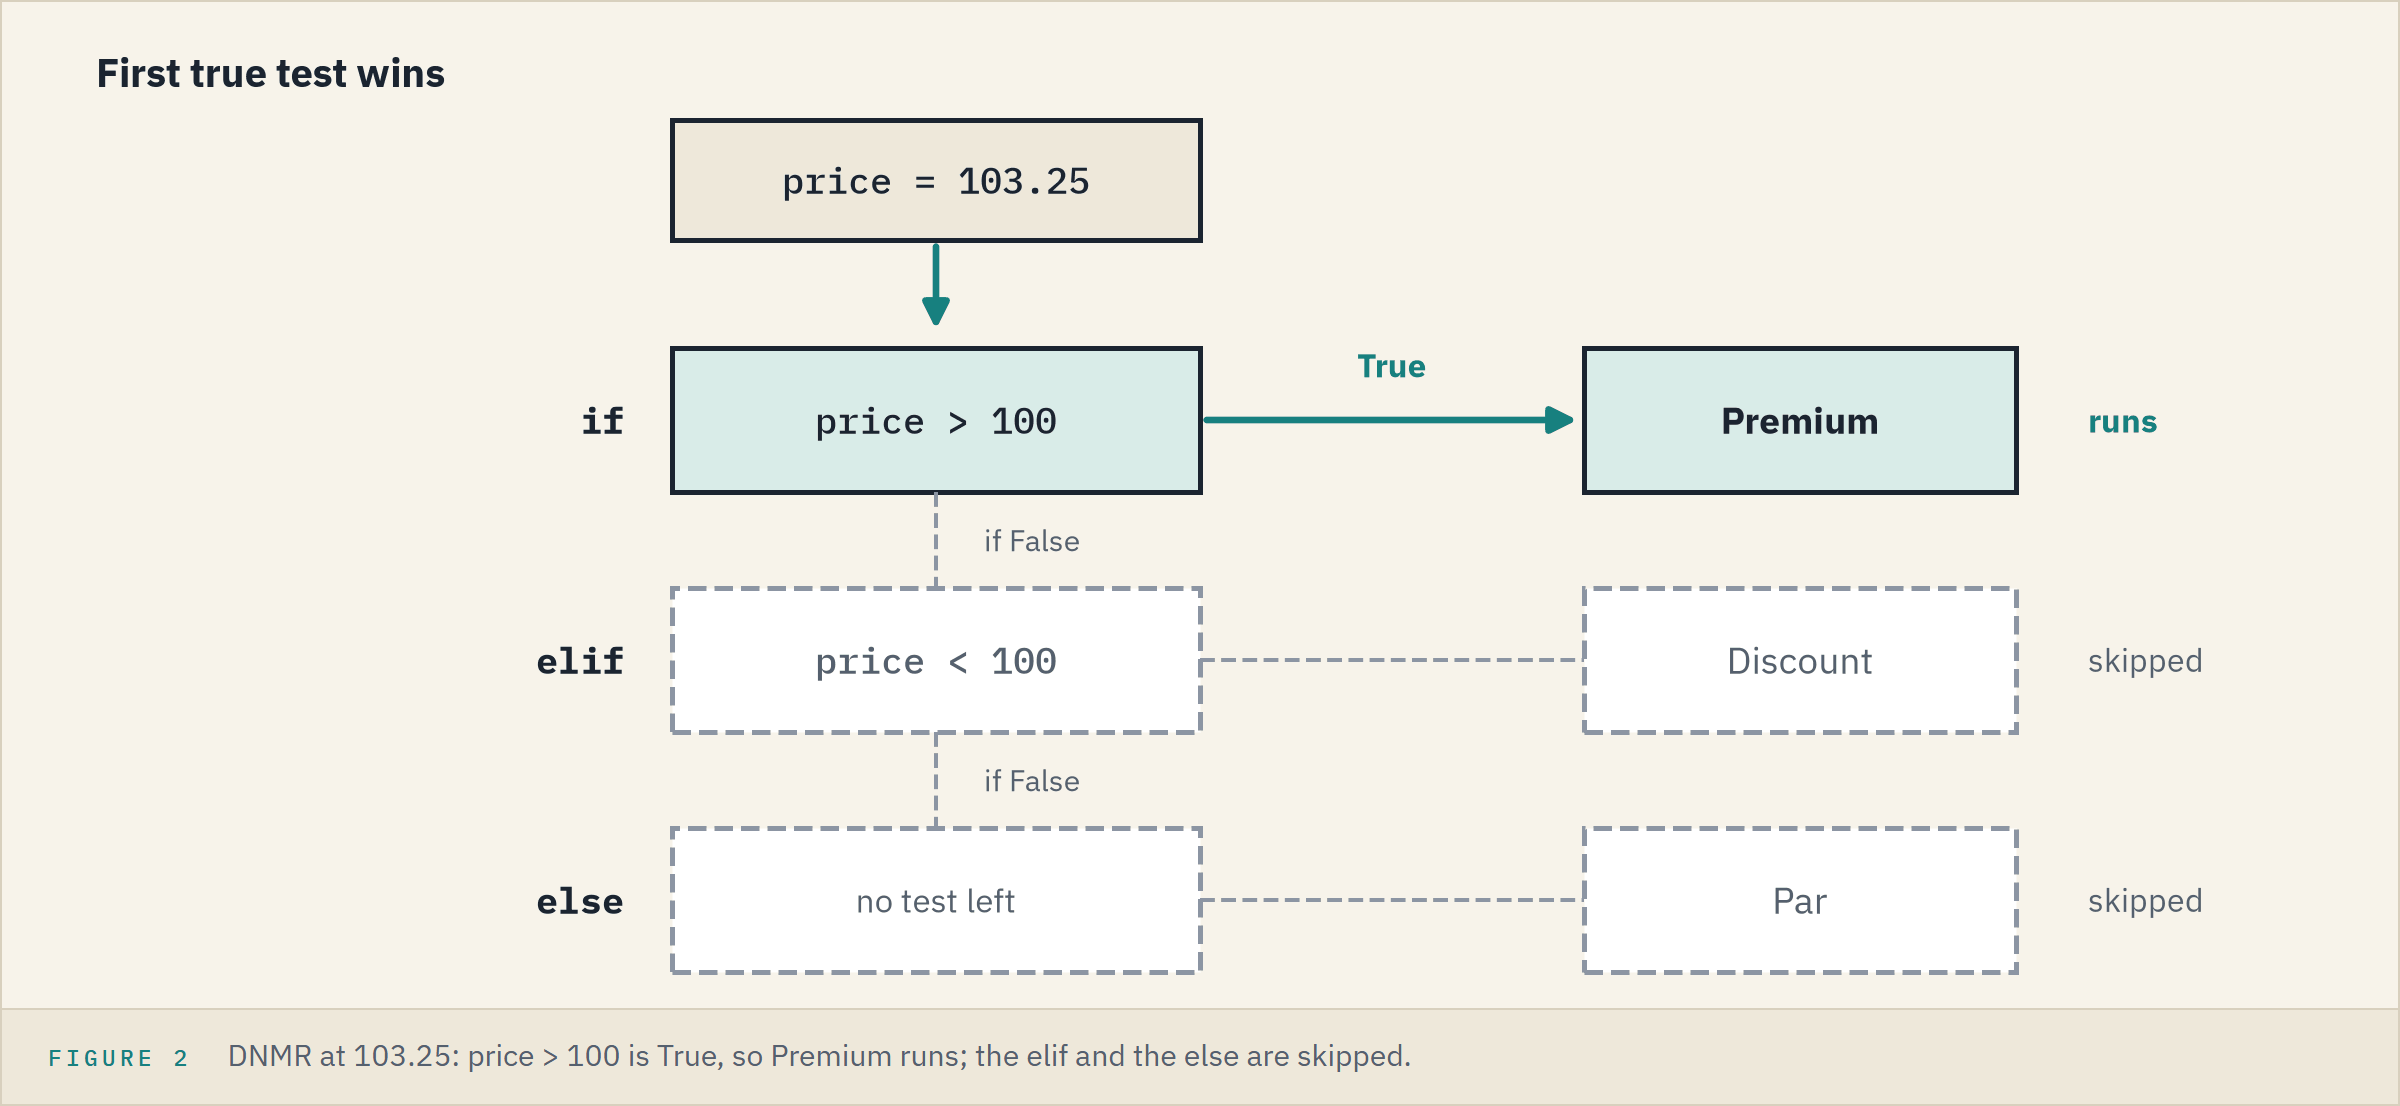

The tests are checked from the top: the first true one runs, the rest are skipped.
`else` catches what no test caught: here, exactly 100.

**Excel side by side.** With the price in A1, a nested IF: `=IF(A1>100,"Premium",IF(A1<100,"Discount","Par"))`.

**Price is one test. The note asks about credit quality.**

### Investment Grade or High Yield

Rating letters do not sort in credit order, so the desk scores them: AAA is 1, one more for each notch lower.

Q. Score the four ratings, and decide HLVF, rated B+.

In [4]:
# each rating and its score, in a dictionary as in Part 1
rating_score = {'BBB': 9, 'BB+': 11, 'A-': 7, 'B+': 14}
# HLVF is rated B+: look up its score, then test it
score = rating_score['B+']
if score <= 10:
    print(f'HLVF scores {score}: investment grade')
else:
    print(f'HLVF scores {score}: high yield')

HLVF scores 14: high yield


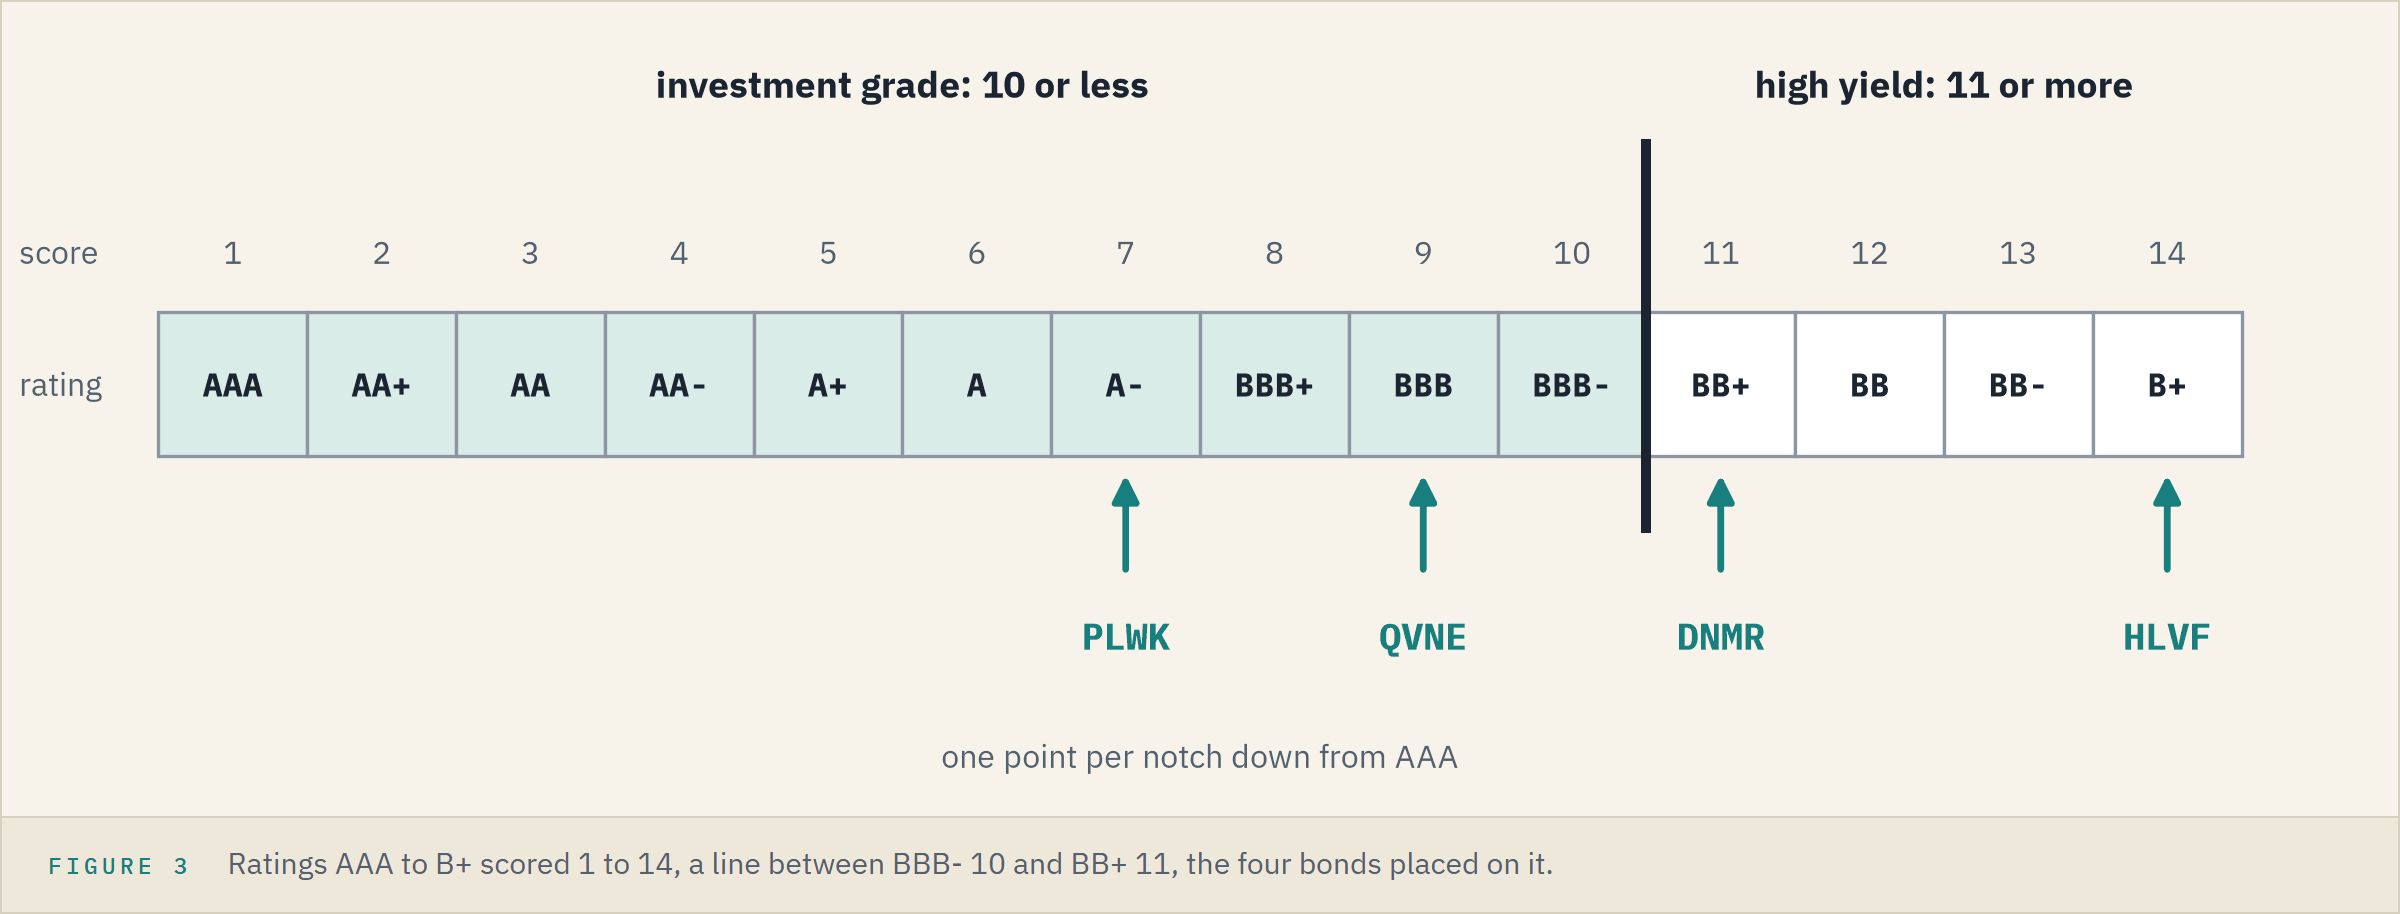

A score of 10 (BBB-) or less is investment grade; HLVF's 14 is past the line, so the `else` block ran.

**`<=` is one comparison. Python has more.**

### Compare and Combine

<table align="left">
<tr><th align="left">Python</th><th align="left">Asks</th><th align="left">Excel</th></tr>
<tr><td align="left"><code>==</code></td><td align="left">equal?</td><td align="left"><code>=</code></td></tr>
<tr><td align="left"><code>!=</code></td><td align="left">not equal?</td><td align="left"><code>&lt;&gt;</code></td></tr>
<tr><td align="left"><code>&lt;</code> and <code>&lt;=</code></td><td align="left">less? less or equal?</td><td align="left"><code>&lt;</code> and <code>&lt;=</code></td></tr>
<tr><td align="left"><code>&gt;</code> and <code>&gt;=</code></td><td align="left">greater? greater or equal?</td><td align="left"><code>&gt;</code> and <code>&gt;=</code></td></tr>
<tr><td align="left"><code>in</code> and <code>not in</code></td><td align="left">one of the items?</td><td align="left"><code>=COUNTIF(A1:A4,"DNMR")&gt;0</code></td></tr>
<tr><td align="left"><code>and</code></td><td align="left">both sides true?</td><td align="left"><code>=AND(A1&gt;10,B1&gt;100)</code></td></tr>
<tr><td align="left"><code>or</code></td><td align="left">at least one side true?</td><td align="left"><code>=OR(A1&lt;=10,B1&gt;100)</code></td></tr>
<tr><td align="left"><code>not</code></td><td align="left">flips True and False</td><td align="left"><code>=NOT(A1&lt;=10)</code></td></tr>
</table>
<br clear="left">

Q. DNMR is rated BB+ and priced at 103.25. Put the comparisons to it.

Q. Is DNMR investment grade and above par? Investment grade or above par?

Q. The desk flags a bond on the line, BBB- or BB+ (score 10 or 11). Is DNMR flagged?

In [5]:
# DNMR's score; three tests in one print: ==, !=, <=
score = rating_score['BB+']
print(score == 11, score != 11, score <= 10)
# in asks whether a value is one of a list's items
print('DNMR' in ticker_list, 'ZZZZ' not in ticker_list)

True False False
True True


In [6]:
# and: both sides must be true; or: at least one. DNMR's price first
price = 103.25
print('Investment grade and above par:', score <= 10 and price > 100)
print('Investment grade or above par:', score <= 10 or price > 100)
# not flips the answer
print('Not investment grade:', not score <= 10)

Investment grade and above par: False
Investment grade or above par: True
Not investment grade: True


In [7]:
# or inside an if: either score puts the bond on the line
if score == 10 or score == 11:
    print('DNMR sits on the investment grade line')
else:
    print('DNMR is clear of the line')

DNMR sits on the investment grade line


`==`, two equals signs, tests; one `=` stores.
`in` on a list asks "do we hold it?", as it asked of text in Part 1.
`and` needs both sides, so it says False; `or` needs one, so the same two tests say True; `not` flips False to True.
DNMR's 11 passes the flag's second test.

**Sometimes the value is not there at all.**

### Missing, Empty, or False

Q. A second agency's rating for QVNE has not arrived. Store that, and test for it.

Q. Which values does Python count as False?

In [8]:
# None, Part 1's value for "nothing here", with no quotes
second_rating = None
# is None asks whether the name holds None
if second_rating is None:
    print('The second rating is missing')
else:
    print(f'The second rating is {second_rating}')

The second rating is missing


In [9]:
# bool() shows whether Python counts a value as True or False
print(bool(0), bool(''), bool([]), bool(None))
print(bool(98.5), bool('QVNE'), bool([98.5]))
# the list itself is the test; with no else, a false test runs nothing
if face_list:
    print(f'The list holds {len(face_list)} positions')

False False False False
True True True
The list holds 4 positions


`None` is not zero and not empty text: it marks a value that is not there.

**Excel side by side.** An empty cell is the nearest thing, but not the same:

<table align="left">
<tr><th align="left">Ask</th><th align="left">Excel empty cell</th><th align="left">Python <code>None</code></th></tr>
<tr><td align="left">Is it empty?</td><td align="left"><code>=ISBLANK(A1)</code></td><td align="left"><code>second_rating is None</code></td></tr>
<tr><td align="left">Add 1</td><td align="left"><code>=A1+1</code> gives 1: blank counts as 0</td><td align="left"><code>None + 1</code> is a <code>TypeError</code></td></tr>
<tr><td align="left">A formula returning <code>""</code></td><td align="left"><code>ISBLANK</code> says FALSE</td><td align="left"><code>''</code> is empty text, not <code>None</code></td></tr>
</table>
<br clear="left">

Zero, empty text `''`, an empty list `[]`, and `None` count as False; other numbers, text, and lists count as True.
So `if face_list:` reads "if the list is not empty".

**That decides one bond at a time. Four bonds need a loop.**

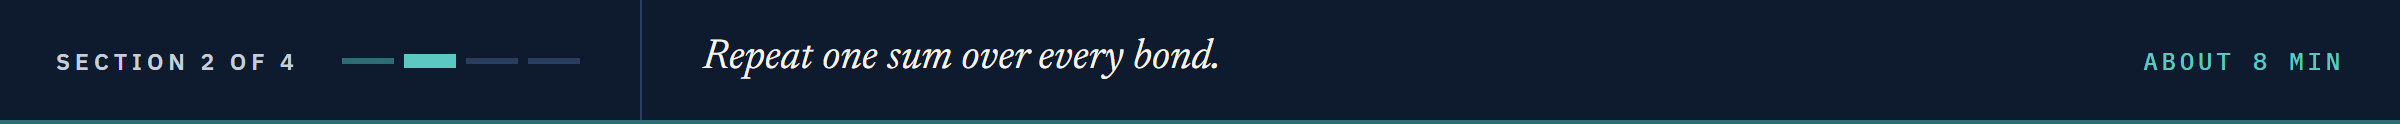

## 1.7 Looping Statements

### Value One Position at Five Prices

The desk asks what the 1,500,000 face of QVNE is worth at 96, 97, 98, 99, and 100.
Five copies of one sum would be slow, with room for a typo in each.
`range()` makes the five numbers, and a **for loop** runs its block once for each:

```
for item in sequence:
    lines to repeat
```

Q. First, what is inside a range?

Q. Then walk 96 to 100.

In [10]:
# a range hides its numbers; list() lays them out, from 0, stopping before 5
print(range(5), list(range(5)))
# start at 96, stop before 101; a third number is the step
print(list(range(96, 101)), list(range(90, 101, 5)))

range(0, 5) [0, 1, 2, 3, 4]
[96, 97, 98, 99, 100] [90, 95, 100]


In [11]:
# QVNE's face; test_price takes each number of the range in turn
face = 1500000
for test_price in range(96, 101):
    # the indented lines run once per number
    value = face * test_price / 100
    print(f'At {test_price} the position is worth ${value:,.2f}')

At 96 the position is worth $1,440,000.00
At 97 the position is worth $1,455,000.00
At 98 the position is worth $1,470,000.00
At 99 the position is worth $1,485,000.00
At 100 the position is worth $1,500,000.00


`range(96, 101)` stops before 101, like a slice in Part 1.
The block ran five times, `test_price` taking each number in turn.

**A loop can also walk a list, or a dictionary.**

### Walk a List, Then a Dictionary

Q. Print each ticker, then number them from 1.

Q. Print every key of QVNE's `bond` with its value.

In [12]:
# a loop can walk a list directly
for ticker in ticker_list:
    print(ticker)
# enumerate() hands over a counter with each item; start=1 counts from 1
for number, ticker in enumerate(ticker_list, start=1):
    print(f'{number}. {ticker}')

QVNE
DNMR
PLWK
HLVF
1. QVNE
2. DNMR
3. PLWK
4. HLVF


In [13]:
# items() hands over each key with its value
for key, value in bond.items():
    print(f'{key}: {value}')

Ticker: QVNE
Coupon: 5.25
Maturity: 2033
Price: 99.25
Rating: BBB
Sector: Energy


Two names after `for` take the two values handed over each time, in order: the counter, then the ticker.
Without `start=1` the count begins at 0: each item's index.
`bond.items()` hands over a key and its value each time, so two names again: six pairs, the price at Part 1's 99.25 mark.

**The cost needs face and price side by side.**

### Step Through Columns Together

Q. What did each position cost, at face times price over 100?

In [14]:
# zip() hands over one bond's ticker, face, and price at a time
for ticker, face, price in zip(ticker_list, face_list, price_list):
    cost = face * price / 100
    print(f'{ticker} cost ${cost:,.2f}')
# after the loop, face and price keep the last bond's values
print(face, price)

QVNE cost $1,477,500.00
DNMR cost $516,250.00
PLWK cost $712,500.00
HLVF cost $252,500.00
250000 101.0


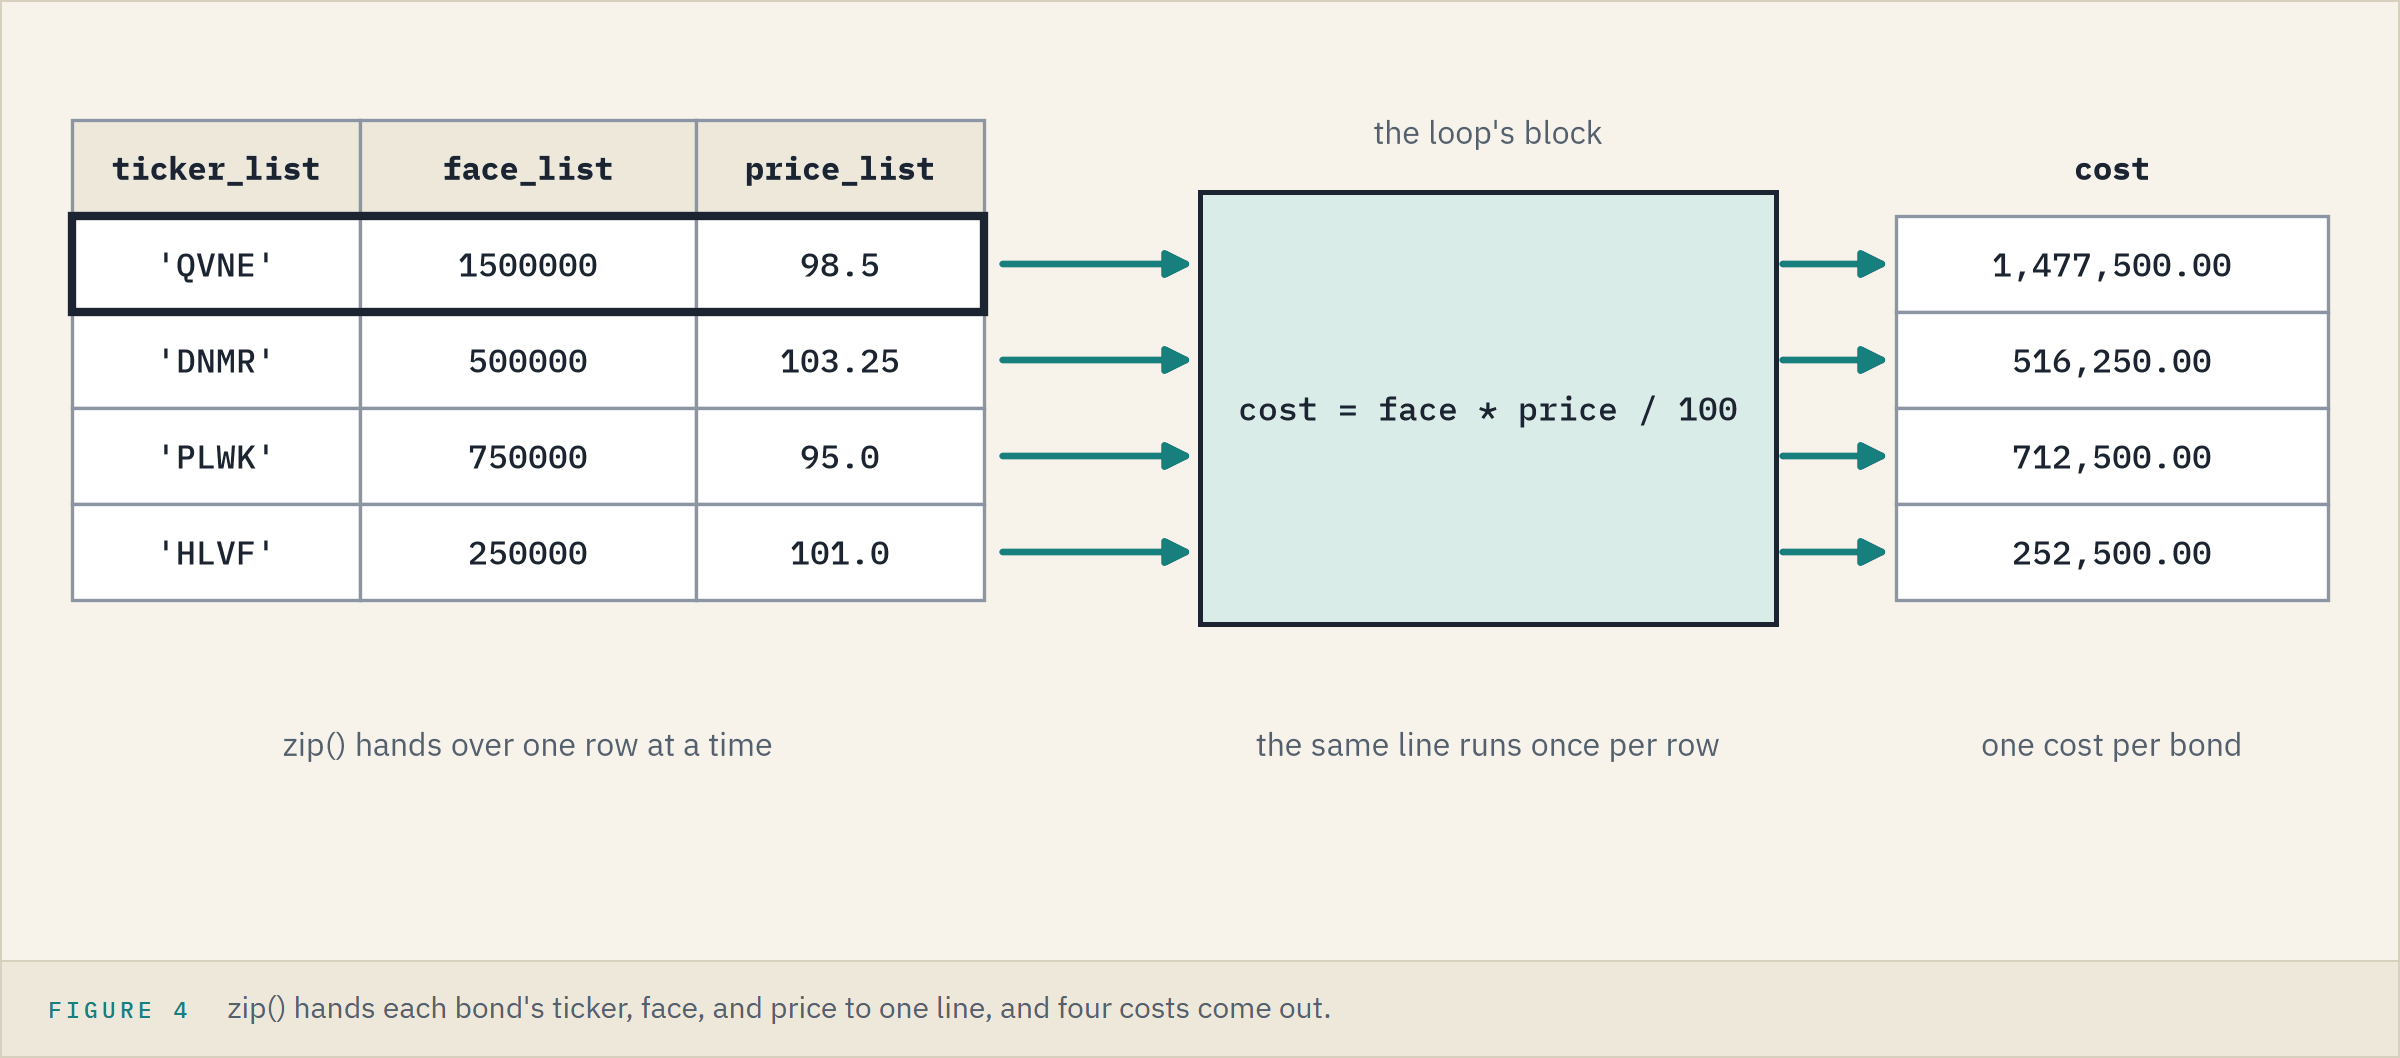

`zip()` lines the lists up item by item, so three names take each bond's three values.
`face` is now 250000, not 1500000: a loop's name replaces an earlier one and keeps its last value.

**Excel side by side.** Type `=B2*C2/100` in one row and fill it down: the loop is the fill-down.

**Put an `if` inside the loop.**

### Decide for Every Bond

Q. Which of the four bonds are investment grade?

In [15]:
for ticker, rating in zip(ticker_list, rating_list):
    # look up the score by the rating, as with bond['Coupon'] in Part 1
    if rating_score[rating] <= 10:
        print(f'{ticker} ({rating}) is investment grade')
    else:
        print(f'{ticker} ({rating}) is high yield')

QVNE (BBB) is investment grade
DNMR (BB+) is high yield
PLWK (A-) is investment grade
HLVF (B+) is high yield


Two indents: the `if` belongs to the loop, each `print` to its branch.
The note's first answer: QVNE and PLWK are investment grade.

**Now one number for the whole book.**

### A Running Total

Q. What did the whole book cost, at the clean price?

In [16]:
# start at zero, then add each position's cost, as in Part 1
total_cost = 0
for face, price in zip(face_list, price_list):
    total_cost += face * price / 100
# not indented: runs once, after the loop
print(f'The book cost ${total_cost:,.2f}')

The book cost $2,958,750.00


The note's second answer: 2,958,750.00 dollars.

**Excel side by side.** Faces in B2:B5 and prices in C2:C5: `=SUMPRODUCT(B2:B5,C2:C5)/100` gives it in one cell.

**Some loops cannot know their count in advance.**

### Loop Until a Target Is Met

A **while loop** repeats its block while its test stays true:

```
while test:
    lines to repeat
```

Q. QVNE pays 39,375 dollars every six months. How many payments collect 150,000 dollars?

In [17]:
payment = 39375
collected = 0
payments = 0
while collected < 150000:
    collected += payment
    payments += 1
print(f'{payments} payments collect ${collected:,}')

4 payments collect $157,500


A `for` loop runs a known number of times; a `while` loop runs until something happens.
If its test never turns false, it never stops: click **Interrupt** at the top of the notebook (in Colab, Runtime, then Interrupt execution).

**Loops that build a list have a shorter form.**

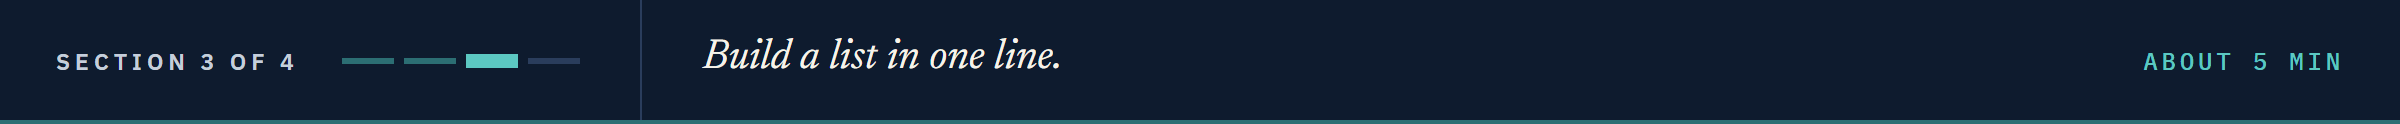

## 1.8 List Comprehensions

### The Same List in One Line

Q. List each position's annual coupon income, in dollars.

A **list comprehension** builds the same list inside one pair of square brackets.

Q. Build `income_list` again, in one line.

In [18]:
# start empty, then append one income per bond
income_list = []
for face, coupon in zip(face_list, coupon_list):
    income_list.append(face * coupon / 100)
print(income_list)

[78750.0, 30625.0, 35625.0, 18750.0]


In [19]:
# what to make, then for each pair, from where
income_list = [face * coupon / 100 for face, coupon in zip(face_list, coupon_list)]
print(income_list)

[78750.0, 30625.0, 35625.0, 18750.0]


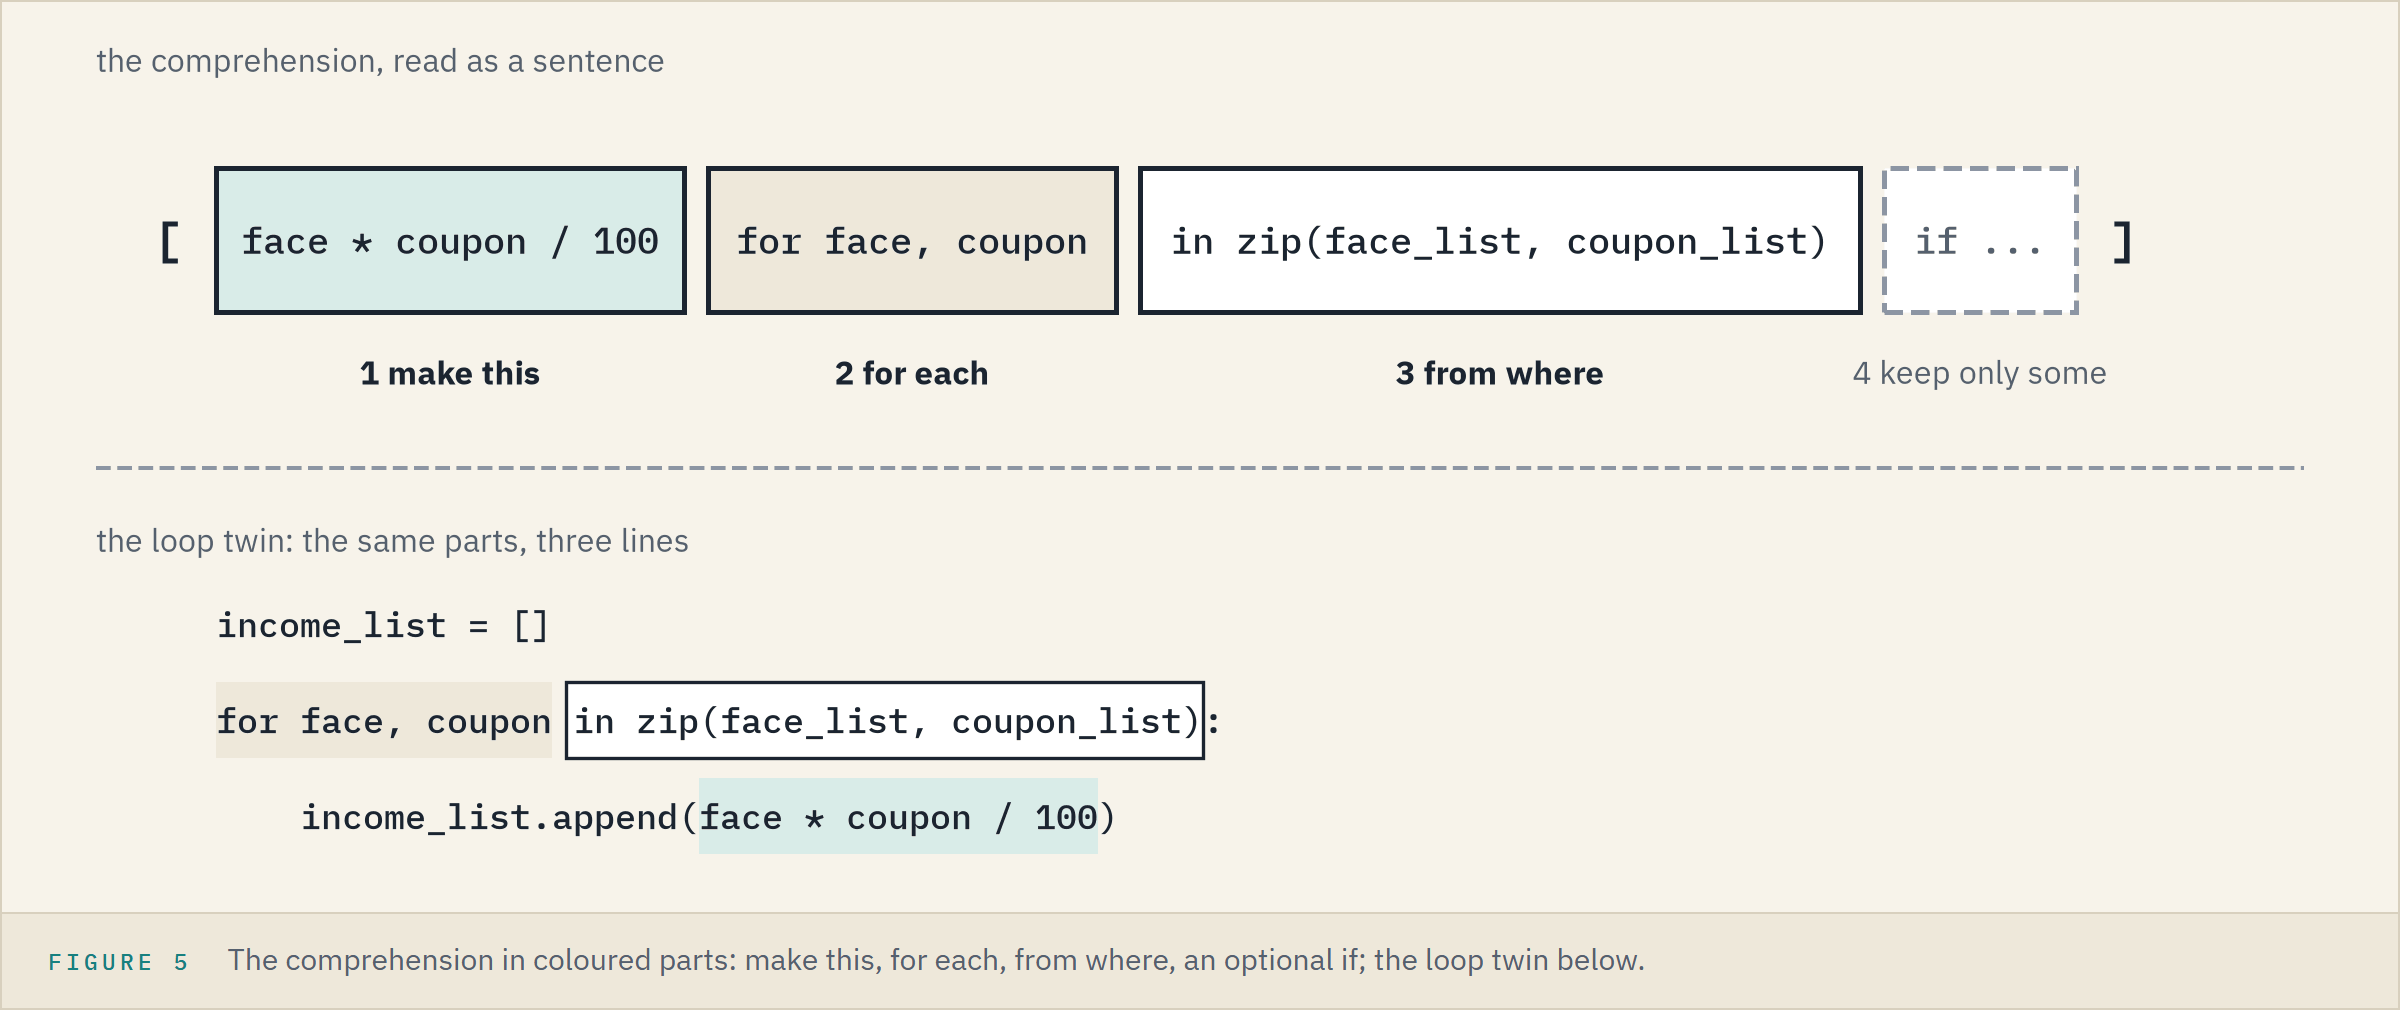

The same four numbers, from one line.

**A comprehension can also choose.**

### Choose a Label

Q. Label each bond Premium or Discount. None of the four sits at exactly 100, so two labels do here.

Q. Then write the same list as a loop.

In [20]:
# value if test else other value: one of two, for each price
label_list = ['Premium' if price > 100 else 'Discount' for price in price_list]
print(label_list)

['Discount', 'Premium', 'Discount', 'Premium']


In [21]:
# the same list, written as a loop
label_list = []
for price in price_list:
    if price > 100:
        label_list.append('Premium')
    else:
        label_list.append('Discount')
print(label_list)

['Discount', 'Premium', 'Discount', 'Premium']


`'Premium' if price > 100 else 'Discount'` is a one-line `if`: the value if true, the test, the value if false.
It sits in the make-this slot of the comprehension picture above: one of two values for every price.

**A comprehension can also keep only some.**

### Keep Only the Bonds That Pass

Q. Which tickers are investment grade?

In [22]:
# an if at the end keeps only the items that pass; the open bracket lets it run onto two lines
ig_tickers = [ticker for ticker, rating in zip(ticker_list, rating_list)
              if rating_score[rating] <= 10]
print(ig_tickers)

['QVNE', 'PLWK']


QVNE and PLWK, as in 1.7.
This `if` sits at the end, with no `else`: it drops the items that fail.

**Excel side by side.** Tickers in A2:A5 and scores in F2:F5: `=FILTER(A2:A5,F2:F5<=10)` keeps the same two; `FILTER` needs Excel 2021 or later, or Microsoft 365.

**The income list is ready to draw.**

### Draw the Income

Q. Which bond earns most of the book's coupon?

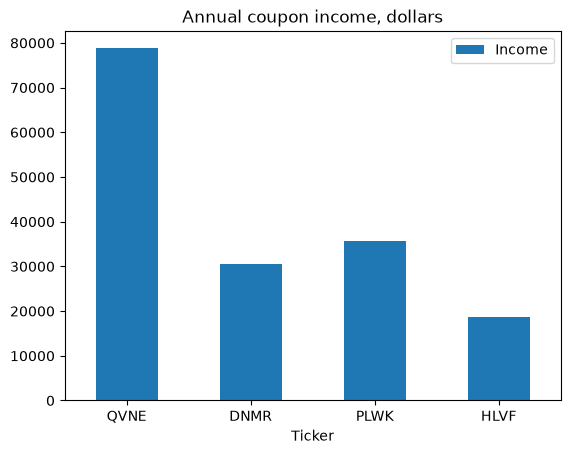

In [23]:
# pandas, imported as in Day 0
import pandas as pd

# a dictionary of lists becomes a table, as in Part 1
table = pd.DataFrame({'Ticker': ticker_list, 'Income': income_list})
# a bar chart of each bond's annual income, tickers upright
chart = table.plot.bar(x='Ticker', y='Income', rot=0, title='Annual coupon income, dollars')

QVNE's bar towers over the rest: 78,750 of the book's 163,750 dollars a year, almost half.

**The coupon sum has now been typed again and again. Make it a tool.**

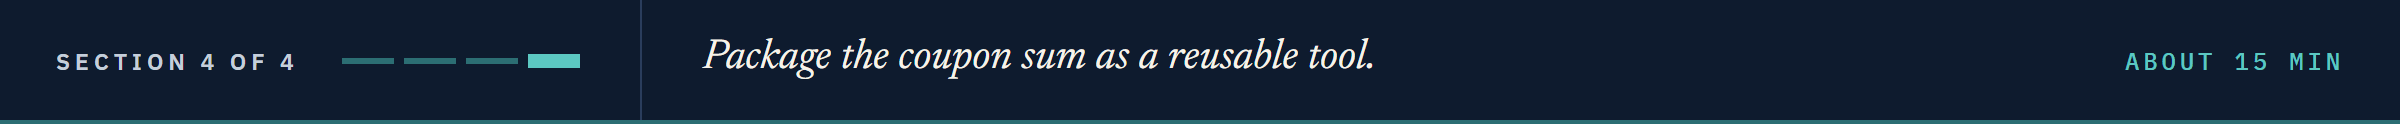

## 1.9 Functions in Python

### Define, Then Call

`print`, `len`, and `sum` are Python's own functions, as in Day 0; you can write your own and reuse it.
The indented lines under the `def` line are the function's **body**.

Q. Write a function that describes QVNE.

In [24]:
# def, the name, round brackets, a colon; then the indented body
def describe_qvne():
    """Print a one-line description of QVNE."""
    print('QVNE 5.25% of 2033 is priced at 98.5')

Nothing printed: defining a function stores it without running it.

Q. So **call** it, by its name and round brackets, then ask Python what it does with `help()`.

In [25]:
# call the function
describe_qvne()
# help() shows a function's name, its inputs, and its docstring
help(describe_qvne)

QVNE 5.25% of 2033 is priced at 98.5
Help on function describe_qvne in module __main__:

describe_qvne()
    Print a one-line description of QVNE.



A function must be defined, by running its cell, before it is called.
The line in triple quotes is a **docstring**: what the function does.
It is not a comment: Python keeps it with the function, and `help()` shows it.
Inside `help()` the name has no brackets: it hands over the function itself, not a call.
`help(len)` works on Python's own functions too; every `def` in this notebook has a docstring.

**`describe_qvne` knows only QVNE.**

### Parameters and Arguments

A **parameter** is a name in the `def` line's brackets that stands for an input; an **argument** is the value a call gives it.

Q. Write one function that describes any bond, and call it for DNMR and PLWK.

Q. What if a call gives three arguments for four parameters?

In [26]:
# four parameters, one for each input
def describe_bond(ticker, coupon, maturity, price):
    """Print a one-line description of any bond."""
    print(f'{ticker} {coupon}% of {maturity} is priced at {price}')

describe_bond('DNMR', 6.125, 2034, 103.25)
describe_bond('PLWK', 4.75, 2031, 95.0)

DNMR 6.125% of 2034 is priced at 103.25
PLWK 4.75% of 2031 is priced at 95.0


In [27]:
# only three arguments: this cell is meant to fail
describe_bond('HLVF', 7.5, 2032)

TypeError: describe_bond() missing 1 required positional argument: 'price'

The arguments fill the parameters in order.
A `TypeError`, and its last line names the missing argument: `price`.

**Printing is not enough when the number is needed later.**

### Hand a Value Back

`return` hands a value back to the call, to be stored or used; `print` only shows it.

Q. Turn the coupon sum into a tool: `annual_income(face, coupon)`.

Q. Store what `describe_bond` hands back, and print it.

In [28]:
def annual_income(face, coupon):
    """Take face and coupon (percent); return a year's coupon income in dollars."""
    return face * coupon / 100

# the value handed back is stored, then printed
qvne_income = annual_income(1500000, 5.25)
print(f'QVNE pays ${qvne_income:,.2f} a year')

QVNE pays $78,750.00 a year


In [29]:
# describe_bond prints, but has no return
result = describe_bond('DNMR', 6.125, 2034, 103.25)
print(result)

DNMR 6.125% of 2034 is priced at 103.25
None


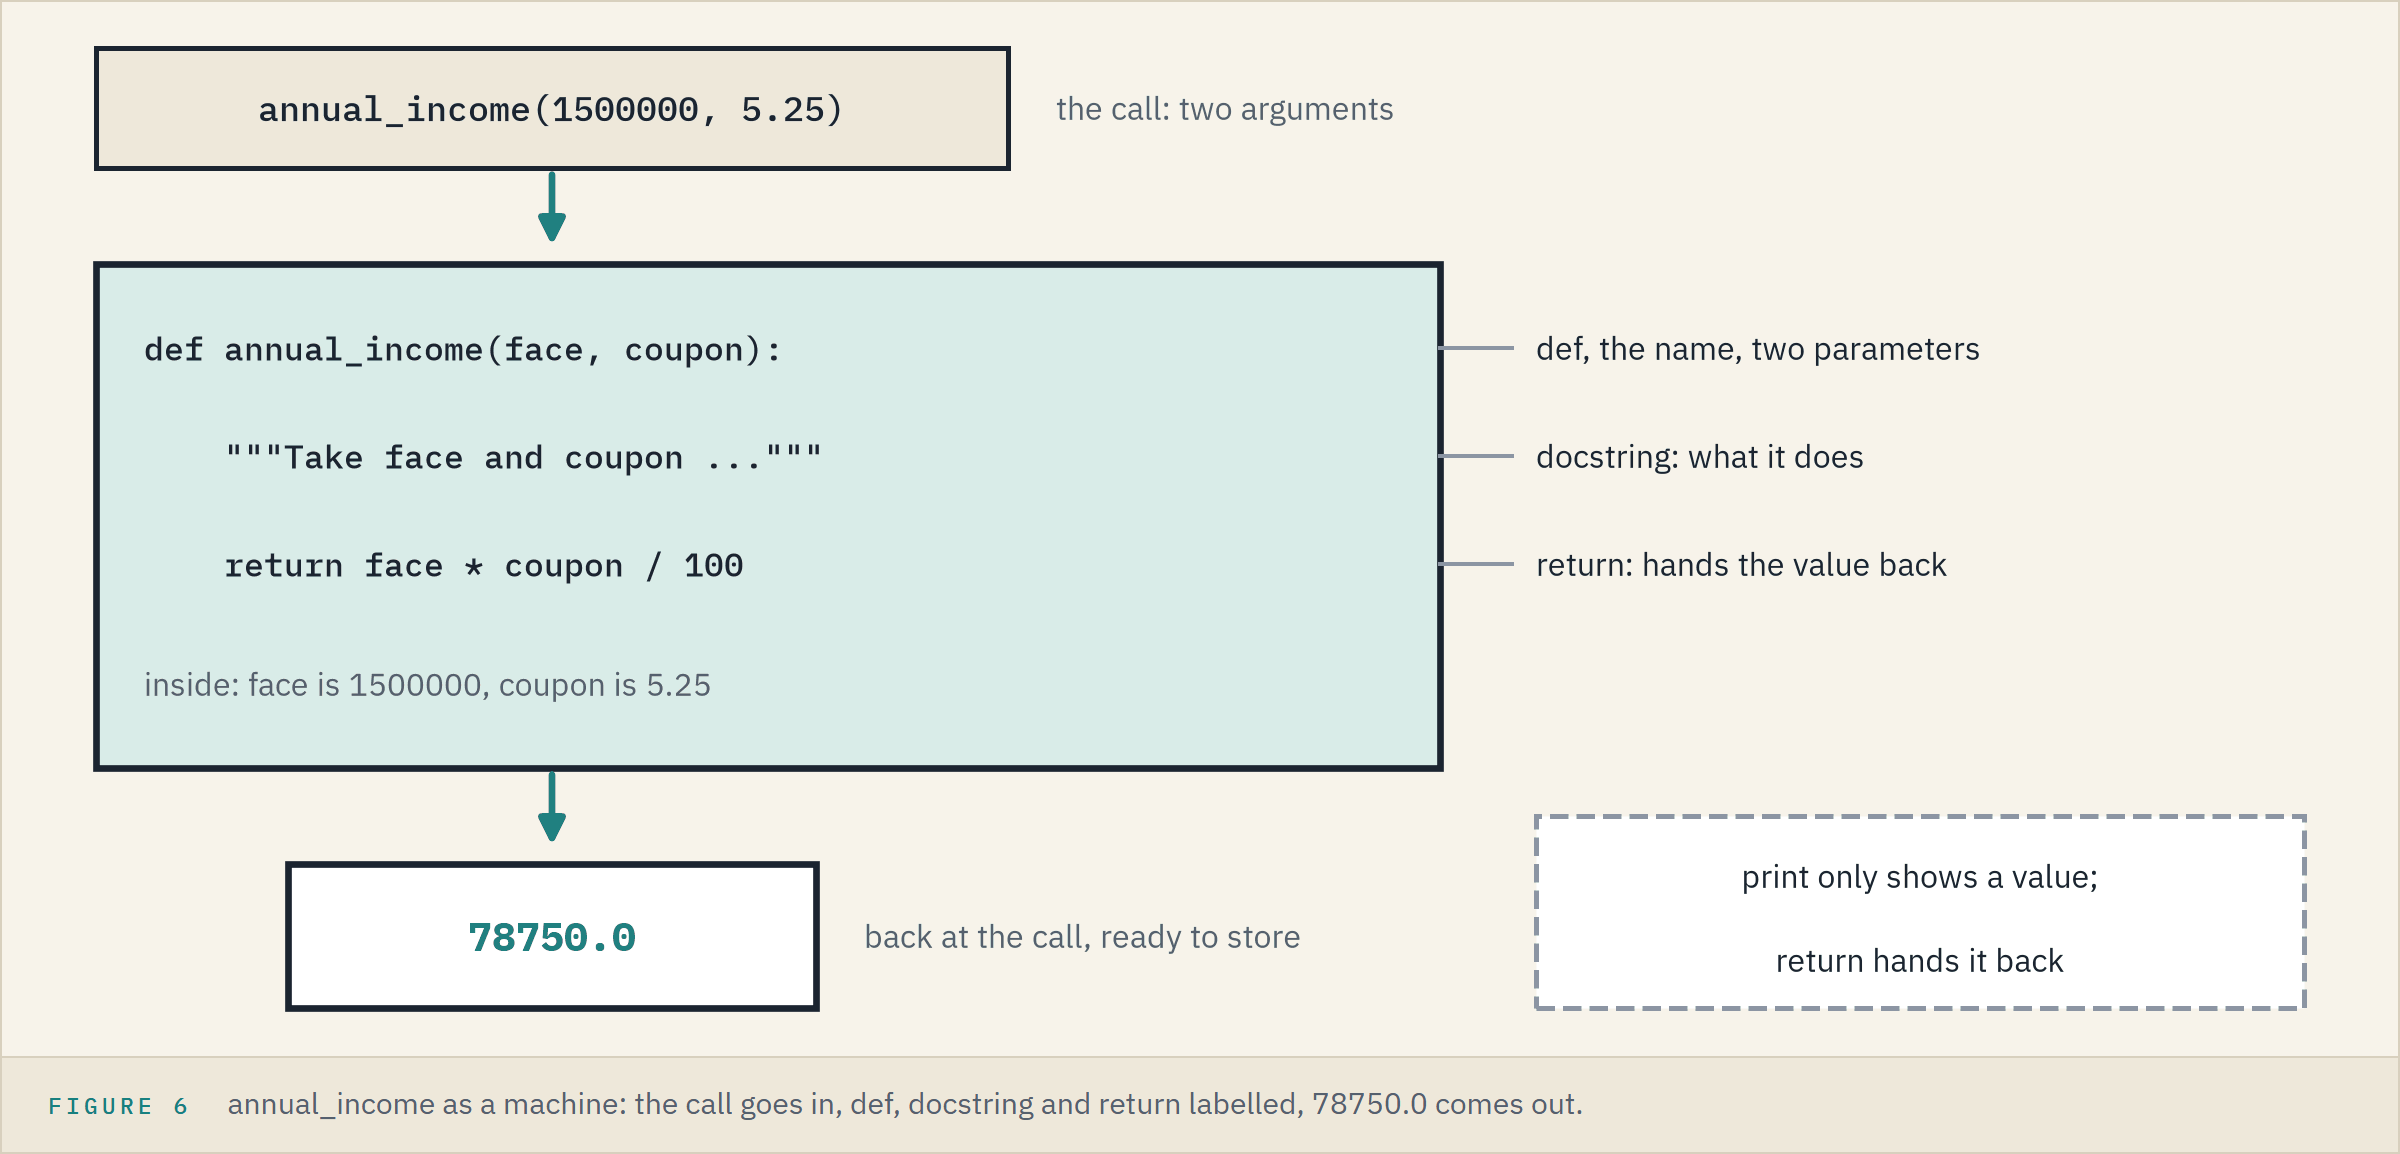

The note's third request: Part 1's `annual_income` was one number for one bond; now the same sum is a tool, called by name for any bond.
Inside the function, `face` and `coupon` are this call's values; the `face` the loop left at 250000 is not touched.
The function printed the first line as it ran; what it handed back is `None`.

**Excel side by side.** In Microsoft 365, `LAMBDA` does this job: in the Name Manager, name `=LAMBDA(face,coupon,face*coupon/100)` as `ANNUAL_INCOME`, and `=ANNUAL_INCOME(1500000,5.25)` gives 78750.

**A returning function works inside a loop.**

### A Function in a Loop

**Current yield** is the annual coupon divided by the price, both per 100 face.

Q. Write `current_yield`, then find each bond's, to 2 decimals.

In [30]:
def current_yield(coupon, price):
    """Take coupon (percent) and price (per 100 face); return current yield in percent."""
    return coupon / price * 100

# call the function for each bond in turn
for ticker, coupon, price in zip(ticker_list, coupon_list, price_list):
    print(f'{ticker}: {current_yield(coupon, price):.2f} percent')

QVNE: 5.33 percent
DNMR: 5.93 percent
PLWK: 5.00 percent
HLVF: 7.43 percent


QVNE's 5.33 sits above its 5.25 coupon because the bond costs less than 100.
`:.2f` changes only the look; Part 1's `round()` changes the number itself: `round(current_yield(5.25, 98.5), 2)` is 5.33.

**Some inputs have a usual value.**

### Defaults and Keywords

An argument matched by its place is a **positional argument**; one passed by name, `name=value`, is a **keyword argument**, like Part 1's `sep=' | '`.
In the `def` line, `name=value` sets a **default**, used when a call leaves that argument out.

Q. Total the book's coupon income for a year, or for fewer months.

Q. Can a keyword argument come before a positional one?

In [31]:
# months has a default of 12, so a call may leave it out
def total_income(incomes, months=12):
    """Take a list of annual incomes and a number of months; return that period's income."""
    return sum(incomes) * months / 12

In [32]:
# months left out: the default, 12
print(f'A year: ${total_income(income_list):,.2f}')
# months given by name
print(f'Six months: ${total_income(income_list, months=6):,.2f}')
# every argument by name, so the order no longer matters
print(f'Three months: ${total_income(months=3, incomes=income_list):,.2f}')

A year: $163,750.00
Six months: $81,875.00
Three months: $40,937.50


In [33]:
# a keyword, then a positional argument: this cell is meant to fail
print(total_income(months=6, income_list))

SyntaxError: positional argument follows keyword argument (3656029623.py, line 2)

A `SyntaxError`: positional arguments must come first, so nothing ran.

**Keywords also steer Python's own functions.**

### Sort a List, Then Bonds by Price

Q. Sort the prices from lowest to highest, then from highest to lowest.

`key=` takes a function: `sorted()` calls it on each item and sorts by what it returns.

Q. Sort `holdings` by price, highest first.

In [34]:
# sorted() hands back a new list, lowest first
print(sorted(price_list))
# reverse=True, a keyword argument, turns the order round
print(sorted(price_list, reverse=True))
# the original keeps the table's order
print(price_list)

[95.0, 98.5, 101.0, 103.25]
[103.25, 101.0, 98.5, 95.0]
[98.5, 103.25, 95.0, 101.0]


In [35]:
def price_of(holding):
    """Take one bond's dictionary; return its price."""
    return holding['Price']

# key= gets the function itself: its name with no brackets
by_price = sorted(holdings, key=price_of, reverse=True)
print([holding['Ticker'] for holding in by_price])

['DNMR', 'HLVF', 'QVNE', 'PLWK']


`sorted()` made new lists; `price_list` is unchanged.
DNMR at 103.25 comes first, PLWK at 95.00 last.
`key=price_of` hands over the function for `sorted()` to call; `price_of()` would call it at once, with no bond.

**Excel side by side.**

<table align="left">
<tr><th align="left">Python</th><th align="left">Excel</th></tr>
<tr><td align="left"><code>sorted(price_list)</code></td><td align="left"><code>=SORT(A1:A4)</code></td></tr>
<tr><td align="left"><code>sorted(price_list, reverse=True)</code></td><td align="left"><code>=SORT(A1:A4,1,-1)</code></td></tr>
<tr><td align="left"><code>sorted(holdings, key=price_of, reverse=True)</code></td><td align="left"><code>=SORTBY(A1:A4,C1:C4,-1)</code>, tickers in A by prices in C</td></tr>
</table>
<br clear="left">

`SORT` and `SORTBY` need Excel 2021 or later, or Microsoft 365, and leave the original cells alone; in any version, the Sort buttons on the Data tab reorder the cells themselves.

**Other people write that key in one line.**

### Read It in Others' Code

Read these three; you need not write them yet.

Libraries, colleagues, and AI answers use them all the time.

<table align="left">
<tr><th align="left">Form</th><th align="left">What it is</th><th align="left">Usually seen</th></tr>
<tr><td align="left"><code>lambda</code></td><td align="left">a one-line function with no name; it hands back its expression without the word <code>return</code></td><td align="left">as a <code>key=</code></td></tr>
<tr><td align="left"><code>*args</code></td><td align="left">one star: any number of values, arriving as a tuple</td><td align="left">in a <code>def</code> line</td></tr>
<tr><td align="left"><code>**kwargs</code></td><td align="left">two stars: any number of keyword arguments, arriving as a dictionary</td><td align="left">in a <code>def</code> line</td></tr>
</table>
<br clear="left">

Q. Write the price sort's key as a `lambda`.

Q. Total any number of face amounts.

Q. Add any named cash amounts to a period's coupon.

In [36]:
# the same sort, with the key written as a lambda
by_price = sorted(holdings, key=lambda holding: holding['Price'], reverse=True)
print([holding['Ticker'] for holding in by_price])

['DNMR', 'HLVF', 'QVNE', 'PLWK']


In [37]:
def add_face(*positions):
    """Take any number of face amounts; return their total."""
    return sum(positions)

# four values, then six: the same function takes both
print(f'{add_face(1500000, 500000, 750000, 250000):,}')
print(f'{add_face(1500000, 500000, 750000, 250000, 300000, 200000):,}')

3,000,000
3,500,000


In [38]:
def net_cash(income, **other_cash):
    """Take a period's coupon income and any named cash amounts; return the net cash."""
    # other_cash is a dictionary: add its values, whatever their names
    return income + sum(other_cash.values())

# money in is positive, money out negative
print(f'${net_cash(81875.0, maturing_bond=250000, custody_fees=-1500):,.2f}')

$330,375.00


`lambda holding: holding['Price']` reads: take a holding, hand back its price; the same list `price_of` gave.
Six months of coupon, plus a maturing bond, less custody fees: names the function never knew in advance.
`*positions` and `**other_cash` use the same stars as `*args` and `**kwargs`; the name after the stars is yours to choose.

**One last function answers the whole note.**

### The Book in One Call

Q. Write one function that hands back the book's total face, total cost, and total annual income.

In [39]:
def portfolio_summary(faces, prices, coupons):
    """Take lists of face, price, and coupon; return total face, cost, and annual income."""
    cost = 0
    income = 0
    for face, price, coupon in zip(faces, prices, coupons):
        cost += face * price / 100
        income += annual_income(face, coupon)
    # three values, handed back together as a tuple
    return sum(faces), cost, income

In [40]:
# three names take the tuple's three values, in order
book_face, book_cost, book_income = portfolio_summary(face_list, price_list, coupon_list)
print(f'Total face: {book_face:,}')
print(f'Total cost: ${book_cost:,.2f}')
print(f'Annual income: ${book_income:,.2f}')

Total face: 3,000,000
Total cost: $2,958,750.00
Annual income: $163,750.00


2,958,750.00 matches 1.7's running total, and 163,750.00 is the chart's bars added up.
`annual_income`, the tool from Hand a Value Back, now works inside another function.
Any book held in three lists is now one call away.

**Decide, repeat, package: now try them yourself.**

## You Can Now

By the end of this notebook, you can:

* Label a bond: premium or discount, investment grade or high yield.
* Repeat a calculation over every bond, and keep a running total.
* Build a list in one line, choosing or filtering as it goes, and draw it.
* Write a function with parameters, a default, and a `return`.
* Sort a list, and read `lambda`, `*args`, and `**kwargs`.

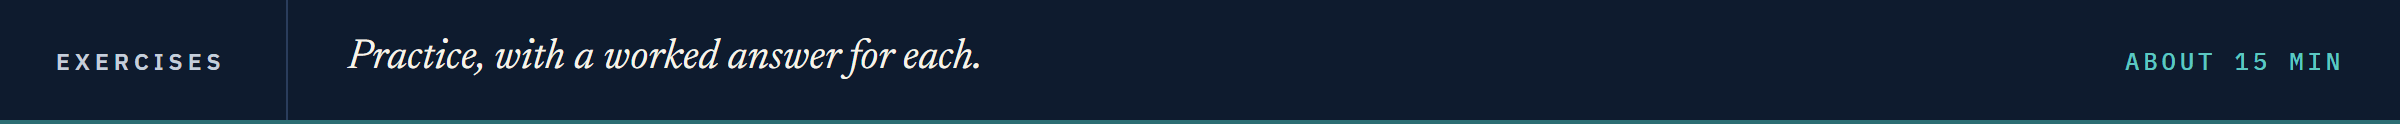

## Exercises

**Every exercise has a worked answer** in the solutions notebook in this folder: the one with this notebook's name ending in `_solutions.ipynb`.

Give each exercise a real try first, then check your work against it.

The exercises use Day 0's three bonds.

<table align="left">
<tr><th align="left">Ticker</th><th align="left">Issuer</th><th align="left">Coupon (%)</th><th align="left">Maturity</th><th align="left">Price</th><th align="left">Rating</th><th align="left">Face held</th></tr>
<tr><td align="left">TRNW</td><td align="left">Tarnwick Utilities</td><td align="left">4.375</td><td align="left">2030</td><td align="left">96.25</td><td align="left">A</td><td align="left">2,000,000</td></tr>
<tr><td align="left">OSMC</td><td align="left">Osmere Chemicals</td><td align="left">5.00</td><td align="left">2035</td><td align="left">100.00</td><td align="left">BBB-</td><td align="left">1,250,000</td></tr>
<tr><td align="left">CLDB</td><td align="left">Calderby Retail</td><td align="left">8.25</td><td align="left">2031</td><td align="left">104.50</td><td align="left">B</td><td align="left">500,000</td></tr>
</table>
<br clear="left">

As in Part 1: run the next cell first (this time it also stores the three bonds), then replace each `...` and run the check cell under it.

In [41]:
def check(label, answer, expected):
    """Compare an exercise answer to the expected value and print the result."""
    if answer is ... or answer is None:
        print(label + ': not attempted yet')
    elif answer == expected:
        print(label + ': correct')
    else:
        print(label + ': not yet. You have', answer)

# the three bonds, in the order of the table
coupon_list = [4.375, 5.0, 8.25]
price_list = [96.25, 100.0, 104.5]
face_list = [2000000, 1250000, 500000]

### Exercise 1

Q. With a loop and `if`, `elif`, `else`, label each bond 'Premium', 'Discount', or 'Par' by its price.
Store the list in **ex1_labels**.

In [42]:
ex1_labels = ...

In [43]:
check('Exercise 1', ex1_labels, ['Discount', 'Par', 'Premium'])

Exercise 1: not attempted yet


### Exercise 2

Q. Write a function **position_cost** that takes a face amount and a price and returns the position's cost.
Then total the three positions' cost with it in a loop, and store the total in **ex2_total_cost**.

In [44]:
def position_cost(face, price):
    """Take the face held and the price (per 100 face); return the cost of the position."""
    return ...


ex2_total_cost = ...

In [45]:
check('Exercise 2 function', position_cost(2000000, 96.25), 1925000.0)
check('Exercise 2 total cost', ex2_total_cost, 3697500.0)

Exercise 2 function: not attempted yet
Exercise 2 total cost: not attempted yet


### Exercise 3

Q. With a list comprehension, list each position's annual coupon income in dollars, and store it in **ex3_incomes**.

In [46]:
ex3_incomes = ...

In [47]:
check('Exercise 3', ex3_incomes, [87500.0, 62500.0, 41250.0])

Exercise 3: not attempted yet


### Exercise 4

Q. Finish **coupon_income**: it takes a face amount, a coupon in percent, and a number of months that defaults to 12, and returns that period's coupon income in dollars.

In [48]:
def coupon_income(face, coupon, months=12):
    """
    Take the face held, the coupon (in percent), and the number of months,
    and return the coupon income for that period in dollars.
    """
    return ...

In [49]:
check('Exercise 4 full year', coupon_income(2000000, 4.375), 87500.0)
check('Exercise 4 six months', coupon_income(2000000, 4.375, months=6), 43750.0)

Exercise 4 full year: not attempted yet
Exercise 4 six months: not attempted yet


### Exercise 5: AI check

You asked an AI assistant for code that totals the face of the three positions; its answer has one bug.

Q. Read the code before you run it. What will it print? Then run it.

In [50]:
# written for this course in the style of an AI assistant's answer. It contains one bug.
face_list = [2000000, 1250000, 500000]

for face in face_list:
    total_face = 0
    total_face = total_face + face

print(f'The total face held is {total_face:,}')

The total face held is 500,000


Q. Is that believable? Add up the three faces in the table yourself, find the bug, and store the right total in **ex5_total_face**.

In [51]:
ex5_total_face = ...

In [52]:
check('Exercise 5', ex5_total_face, 3750000)

Exercise 5: not attempted yet


## Congratulations!

This morning the book sat still in Python.
Now it works, and the note is answered:

<table align="left">
<tr><th align="left">The note asked</th><th align="left">Answer</th></tr>
<tr><td align="left">Which bonds are investment grade</td><td align="left">QVNE and PLWK; DNMR and HLVF are high yield</td></tr>
<tr><td align="left">Cost every position in one go</td><td align="left">one loop: 2,958,750.00 dollars</td></tr>
<tr><td align="left">Make the coupon sum reusable</td><td align="left"><code>annual_income(face, coupon)</code>: 78,750.00 dollars a year for QVNE</td></tr>
</table>
<br clear="left">

Decide, repeat, package: most of the code you will ever write is built from these three, and you just used all of them on a book of bonds.
Be proud of that.
Today the book lives only while the notebook runs.
On Day 2 the book leaves the notebook: you write the holdings to a file in a folder of their own and read them back, with today's loops doing the walking.

[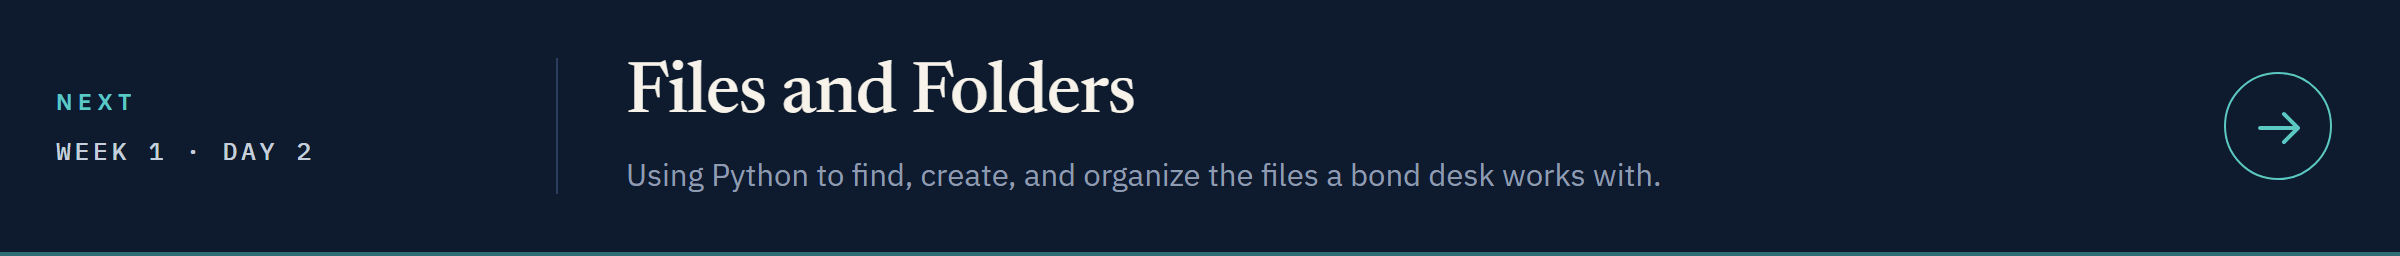](../day2/02_files_and_folders.ipynb)

[Open Day 2 in Colab](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course01_python_foundations/week1/day2/02_files_and_folders.ipynb)